In [1]:
##############
## INITIATE ##
##############

## Imports
import numpy as np
import pandas as pd
from sklearn.metrics import pairwise_distances
from scipy.cluster.hierarchy import linkage, fcluster
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2

## Figure parameters
plt.rcParams['figure.dpi'] = 300
figsize = (14,5)
custom_params = {'axes.spines.right': False, 
                 'axes.spines.top': False, 
                 'axes.facecolor':'whitesmoke'
                }
sns.set_theme(style="ticks", rc=custom_params)

#
###

In [5]:
###########################
## SCRIPT CONFIGURATIONS ##
###########################

## Define paths to embeddings
pti = '/Volumes/Elements/BDI/projects/GSG/outputs/o2_embeddings/icgc-c/model_resnet_icgcc_raw_FTL_0/'
# pti = '/Users/user/Documents/projects/GlandSeg/outputs/V2/o2_embeddings/tcga_ffpes/model_resnet_tcga_raw_FTL_0/'
embeddings_path = pti + 'embeddings.npy'
identifiers_path = pti + 'image_identifiers.csv'

## Define paths to images
dataset_path = '/Volumes/Elements/BDI/projects/GSG/outputs/o1_extracted_glands/icgc-c/'
# dataset_path = '/Users/user/Documents/projects/GlandSeg/outputs/V2/o1_extracted_glands/tcga_ffpes_V1'
# dataset_path = '/Users/user/Documents/projects/GlandSeg/outputs/V2_0_0_20250120/o1_extracted_glands/debug'

#
###

In [6]:
######################
## LOAD EMBEDDINGS  ##
######################

## Load the embeddings from the .npy file
embeddings = np.load(embeddings_path)

## Load identifiers
identifiers_df = pd.read_csv(identifiers_path)
image_filenames = identifiers_df['filename'].tolist()

## Check the shape of the loaded embeddings and identifiers
print(f'Loaded embeddings shape: {embeddings.shape}')
print(f'Loaded {len(image_filenames)} image identifiers')

#
###

Loaded embeddings shape: (107199, 512)
Loaded 107199 image identifiers


In [7]:
#######################
## FORMAT IDENTIFIER ##
#######################

## Get unique identifiers
split_marker = '.svs' # For TCGA
# split_marker = '_'
image_filenames_short = [fname.split(split_marker)[1] for fname in image_filenames]
# split_marker = '-01' # For TCGA
image_filenames_short = [fname.split(split_marker)[0] for fname in image_filenames] # For TCGA
# image_filenames_long = [fname.split('.svs')[0].replace('.','-') for fname in image_filenames] # For TCGA
unique_ids = np.unique(image_filenames_short)
num_groups = len(unique_ids)
print(num_groups)
# print(image_filenames_long[0])
numeric_ids = np.zeros(len(image_filenames_short))
k = 0
for unique_id in unique_ids:    
    index = np.argwhere(np.array(image_filenames_short) == unique_id)
    numeric_ids[index] = k
    k += 1

## Checks
print(image_filenames_short[0:10])
print(numeric_ids[0:10])

#
###

756
['TB08.0618_V5_01', 'TB08.0618_V5_01', 'TB08.0618_V5_01', 'TB08.0618_V5_01', 'TB08.0618_V5_01', 'TB08.0618_V5_01', 'TB08.0618_V5_01', 'TB08.0618_V5_01', 'TB08.0618_V5_01', 'TB08.0618_V5_01']
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [8]:
########################
## FORMAT COORDINATES ##
########################

## Get unique identifiers
# split_marker = '_'
# image_filenames_short = [fname.split(split_marker)[1] for fname in image_filenames]
split_marker = '__' # For TCGA
image_coords = [fname.split('__')[1].split('_') for fname in image_filenames] # For TCGA
image_coords_short = [[(int(coords[1])+int(coords[0]))/2, (int(coords[3])+int(coords[2]))/2] for coords in image_coords]

## Checks
print(image_filenames_short[5])
# print(image_filenames_long[5])
print(int(image_coords[0][0]))
print(image_coords_short[5])


#
###

TB08.0618_V5_01
1456
[2056.0, 4424.0]


In [9]:
######################
## COLLECT METADATA ##
######################

# Load your CSV file
PT_METADATA = '/Volumes/Elements/BDI/datasets/ICGCC/metadata/metadata_handformatted_v20250405.csv'
df = pd.read_csv(PT_METADATA)  # replace with actual filename

# Ensure 'slide_id' and 'relapse' columns exist
assert 'slide_id' in df.columns and 'relapse' in df.columns, "CSV must contain 'slide_id' and 'relapse' columns."

# Create a dictionary to map slide_id to relapse
slide_to_relapse = dict(zip(df['slide_id'], df['relapse']))

# Map relapse values to image_filenames_short
relapse_values = [slide_to_relapse.get(slide_id, 'NA') for slide_id in image_filenames_short]

## Check
k = np.where(np.array(relapse_values) == 1)[0][0]
print(image_filenames_short[k])
print(relapse_values[k])

#
###

TB08.0949_V4_01
1.0


In [10]:
####################
## SUBSET OBJECTS ##
####################

import random

# Example lists
# image_filenames_short = [...]
# image_coords = [...]
# image_coords_short = [...]
# numeric_ids = [...]

# Ensure all lists are the same length
assert len(image_filenames_short) == len(image_coords) == len(image_coords_short) == len(numeric_ids), "Lists must be the same length."

# Get 10,000 unique random indices
num_samples = 20000
indices = random.sample(range(len(image_filenames_short)), num_samples)

# Use the indices to subset each list
image_filenames = [image_filenames[i] for i in indices] 
image_filenames_short = [image_filenames_short[i] for i in indices]
image_coords = [image_coords[i] for i in indices]
image_coords_short = [image_coords_short[i] for i in indices]
embeddings = [embeddings[i] for i in indices]
numeric_ids = np.array([numeric_ids[i] for i in indices])
relapse_values = np.array([relapse_values[i] for i in indices])

#
###

In [11]:
############################
## STANDARDISE EMBEDDINGS ##
############################

from sklearn.preprocessing import StandardScaler

# Standardize embeddings before clustering
scaler = StandardScaler()
embeddings = scaler.fit_transform(embeddings)

#
###

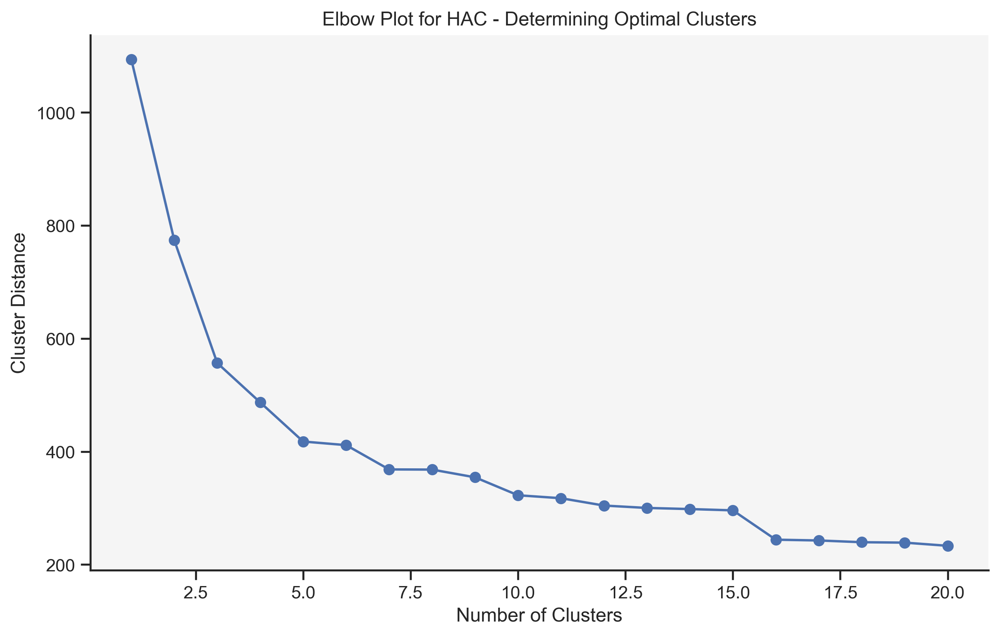

In [12]:
###############################
## PERFORM HAC ON EMBEDDINGS ##
###############################

## Perform hierarchical agglomerative clustering (HAC) on the high-dimensional embeddings
linkage_matrix = linkage(embeddings, method='ward')  ## Using Ward's method for clustering

## Elbow plot to determine the optimal number of clusters
last = linkage_matrix[-20:, 2]
last_rev = last[::-1]
idxs = np.arange(1, len(last) + 1)
plt.figure(figsize=(10, 6))
plt.plot(idxs, last_rev, marker="o")
plt.title('Elbow Plot for HAC - Determining Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Cluster Distance')
plt.grid(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

#
###

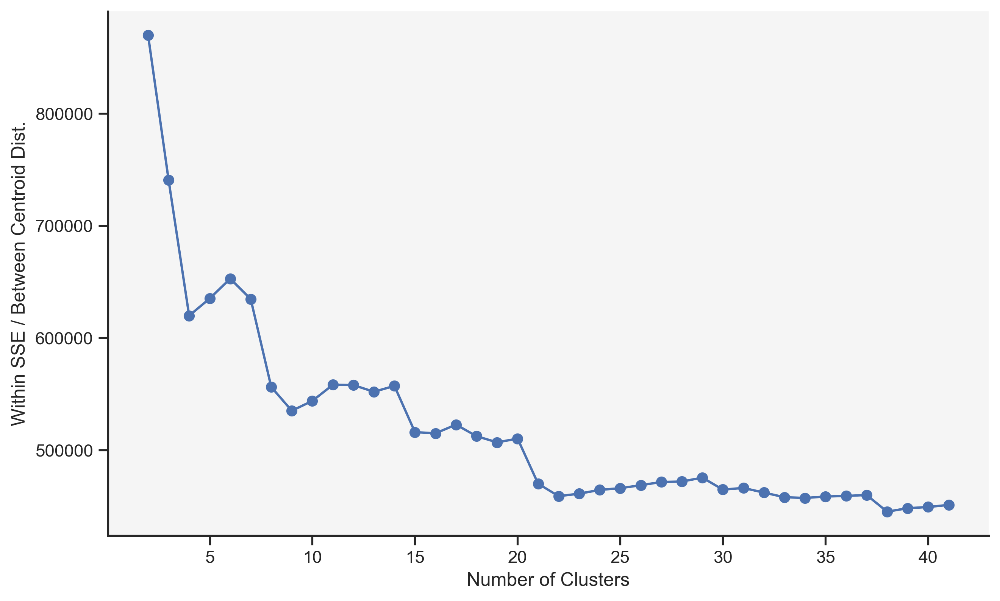

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import fcluster

# assume linkage_matrix and embeddings are already defined

last = linkage_matrix[-40:, 2][::-1]
ks = np.arange(2, len(last) + 2)   # start at 2 clusters

ratios = []
for k in ks:
    labels = fcluster(linkage_matrix, k, criterion='maxclust')
    # centroids
    uniq = np.unique(labels)
    centroids = np.vstack([embeddings[labels==ci].mean(axis=0)
                           for ci in uniq])
    # within-cluster SSE (scalar per cluster)
    w_sse = sum(
        np.sum((embeddings[labels==ci] - c)**2)
        for ci, c in zip(uniq, centroids)
    )
    # between-centroid mean distance
    dmat = np.sqrt(((centroids[:,None] - centroids[None,:])**2).sum(-1))
    i, j = np.triu_indices(len(uniq), k=1)
    b_mean = dmat[i,j].mean()            # now guaranteed non-empty for k>=2

    ratios.append(w_sse / b_mean)

plt.figure(figsize=(10,6))
plt.plot(ks, ratios, marker='o')
# plt.title('Elbow: Within‐SSE / Mean Between‐Centroid Distance')
plt.xlabel('Number of Clusters')
plt.ylabel('Within SSE / Between Centroid Dist.')
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

In [14]:
#########################
## SAVE DATA FOR PLOTS ##
#########################

import os, numpy as np

# compute elbow data
last = ratios
idxs = np.arange(1, len(ratios) + 1)

# user-defined output folder (set to None for current dir)
out_dir = '/Volumes/Elements/BDI/projects/GSG/figures/icgc-c-ft0'  # e.g. 'results/hac' or None
if out_dir:
    os.makedirs(out_dir, exist_ok=True)
base = out_dir or '.'

# save arrays
np.save(f"{base}/hac_elbow_idxs.npy", idxs)
np.save(f"{base}/hac_elbow_distances.npy", last)

#
###

In [15]:
#######################################
## SELECT OPTIMAL NUMBER OF CLUSTERS ##
#######################################

## HAC parameters
num_clusters = 20  ## Set to the optimal number of clusters identified earlier

## Assign cluster labels based on the specified number of clusters
cluster_labels = fcluster(linkage_matrix, num_clusters, criterion='maxclust')

## Check the result
print(f'Cluster labels assigned to {len(cluster_labels)} images')

#
###

Cluster labels assigned to 20000 images


In [16]:
#########################################
## SAVE EMBEDDINGS AND CLUSTER LABELS  ##
#########################################

## Create a dataframe to store the embeddings and their corresponding cluster labels
clustered_data = pd.DataFrame({
    'filename': image_filenames,
    'cluster_label': cluster_labels
})

## Save the cluster labels to a CSV file
output_path = pti + 'image_identifiers_and_reference_clusters.csv'  ## Replace with your desired output path
clustered_data.to_csv(output_path, index=False)

## End
print(f'Clustered data saved to {output_path}')

#
###

Clustered data saved to /Volumes/Elements/BDI/projects/GSG/outputs/o2_embeddings/icgc-c/model_resnet_icgcc_raw_FTL_0/image_identifiers_and_reference_clusters.csv


In [17]:
###########################
## APPLY t-SNE REDUCTION ##
###########################

## Local imports
from sklearn.manifold import TSNE

## t-SNE parameters
n_components = 2  ## Set to 3 for 3D visualization
perplexity = 30  # Similar to UMAP's n_neighbors
learning_rate = 200  # Default recommended learning rate
random_state = 42

## Initialize t-SNE reducer
tsne_reducer = TSNE(n_components=n_components, perplexity=perplexity, learning_rate=learning_rate, random_state=random_state)

## Fit and transform the embeddings
reduced_embeddings = tsne_reducer.fit_transform(embeddings)

## Check the shape of the reduced embeddings
print(f'Reduced embeddings shape: {reduced_embeddings.shape}')

#
###

Reduced embeddings shape: (20000, 2)


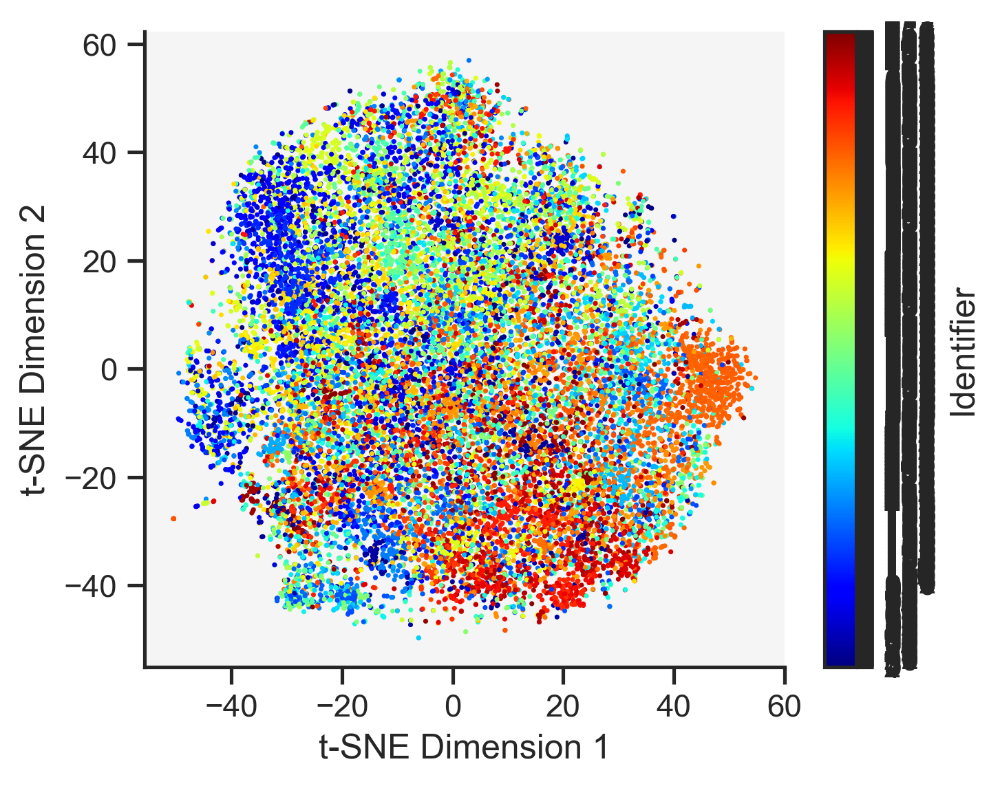

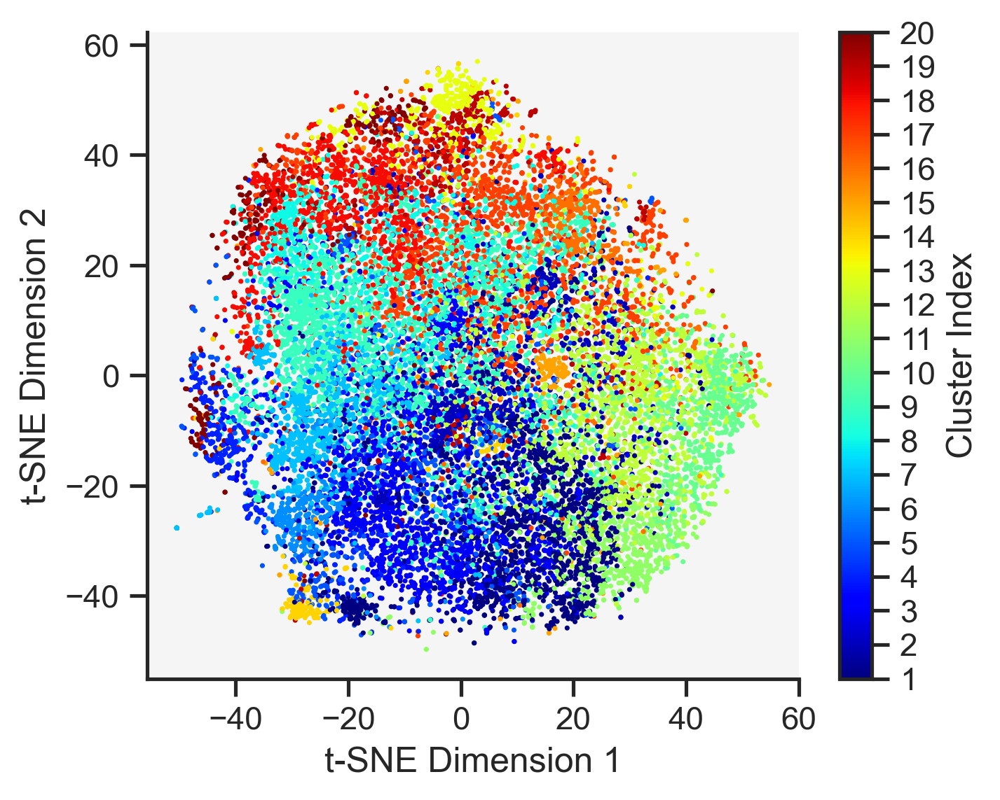

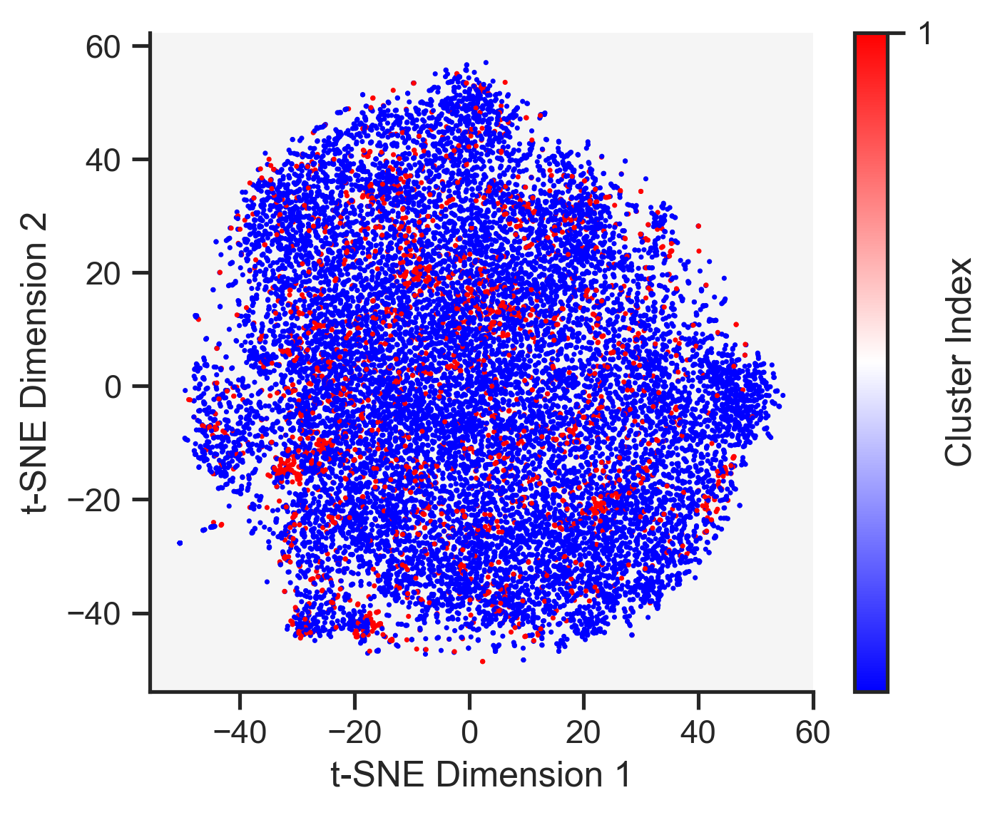

In [19]:
##############################################
## UPDATE t-SNE VISUALIZATION WITH CLUSTERS ##
##############################################

## Parameters
FIGSIZE = (5,4)
POINTSIZE = .5
ALPHA = 1.0

## t-SNE with ID
plt.figure(figsize=FIGSIZE)    
scatter = plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], 
                      c=numeric_ids + 1, cmap='jet', s=POINTSIZE, alpha=ALPHA)    
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.grid(False)
plt.colorbar(scatter, ticks=range(1, num_groups + 1), label='Identifier')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

## t-SNE with cluster index
plt.figure(figsize=FIGSIZE)
scatter = plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], 
                      c=cluster_labels, cmap='jet', s=POINTSIZE, alpha=ALPHA)    
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.grid(False)
plt.colorbar(scatter, ticks=range(1, num_clusters + 1), label='Cluster Index')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

## t-SNE with relapse
plt.figure(figsize=FIGSIZE)
scatter = plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], 
                      c=relapse_values, cmap='bwr', s=POINTSIZE, alpha=ALPHA)    
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.grid(False)
plt.colorbar(scatter, ticks=range(1, num_clusters + 1), label='Cluster Index')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

#
###

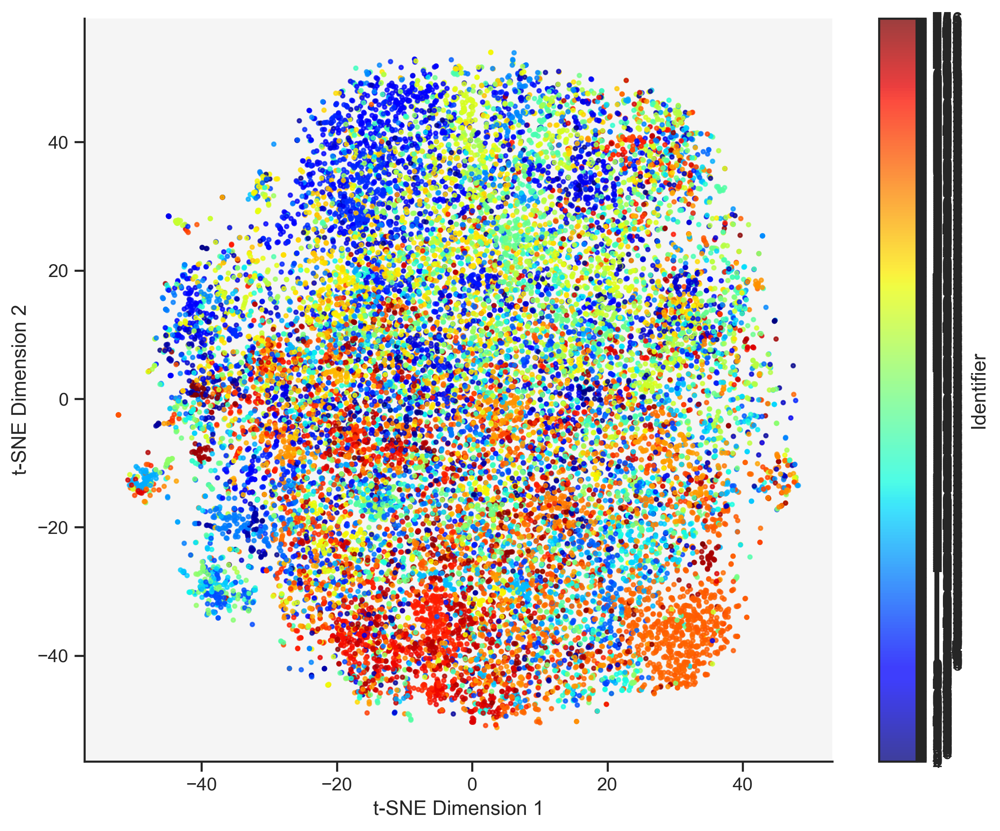

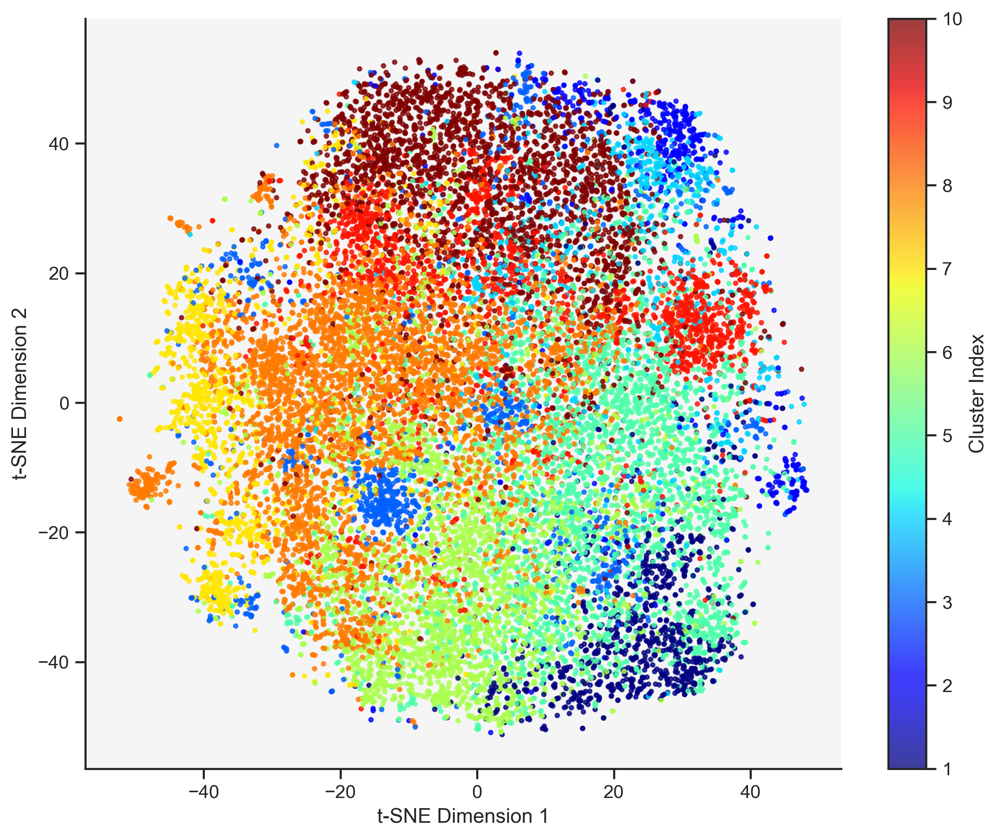

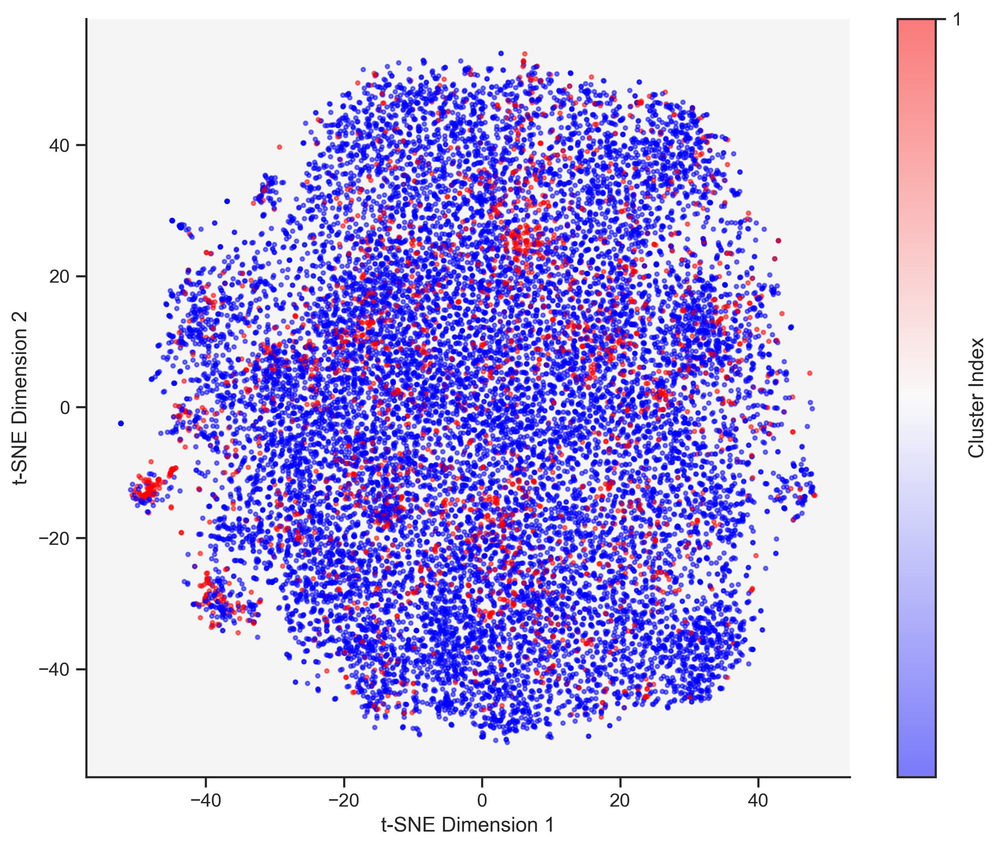

In [18]:
##############################################
## UPDATE t-SNE VISUALIZATION WITH CLUSTERS ##
##############################################

## 2D Visualization with clusters
if n_components == 2:

    ## t-SNE with ID
    plt.figure(figsize=(10, 8))    
    scatter = plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], 
                          c=numeric_ids + 1, cmap='jet', s=5, alpha=0.75)    
    plt.xlabel('t-SNE Dimension 1')
    plt.ylabel('t-SNE Dimension 2')
    plt.grid(False)
    plt.colorbar(scatter, ticks=range(1, num_groups + 1), label='Identifier')
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.show()

    ## t-SNE with cluster index
    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], 
                          c=cluster_labels, cmap='jet', s=5, alpha=0.75)    
    plt.xlabel('t-SNE Dimension 1')
    plt.ylabel('t-SNE Dimension 2')
    plt.grid(False)
    plt.colorbar(scatter, ticks=range(1, num_clusters + 1), label='Cluster Index')
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.show()

    ## t-SNE with relapse
    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], 
                          c=relapse_values, cmap='bwr', s=5, alpha=0.5)    
    plt.xlabel('t-SNE Dimension 1')
    plt.ylabel('t-SNE Dimension 2')
    plt.grid(False)
    plt.colorbar(scatter, ticks=range(1, num_clusters + 1), label='Cluster Index')
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.show()


#
###